## preprocessing data with tensorflow

**import libs**

In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

I0000 00:00:1792337676.695235    8720 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792337676.701667    8720 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792337677.152356    8720 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792337679.756842    8720 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

**loading images**

In [3]:
dataset = keras.utils.image_dataset_from_directory(
    directory='../data/seg_train_test/seg_train',
    image_size=(150,150),
    batch_size=32,
    label_mode='categorical',
    shuffle=True,
    seed=42
)

Found 17034 files belonging to 6 classes.


E0000 00:00:1792337683.663623    8720 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



**spliting to train / validataion / test**

In [4]:
total_batches = int(dataset.cardinality())

train_size = int(0.70 * total_batches)
val_size = int(0.15 * total_batches)

train_ds = dataset.take(train_size)
val_ds = dataset.skip(train_size).take(val_size)
test_ds = dataset.skip(train_size + val_size)

autotune = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=autotune)
val_ds = val_ds.prefetch(buffer_size=autotune)
test_ds = test_ds.prefetch(buffer_size=autotune)


**data augmentations**

In [5]:
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1)
])

# visualize before vs after

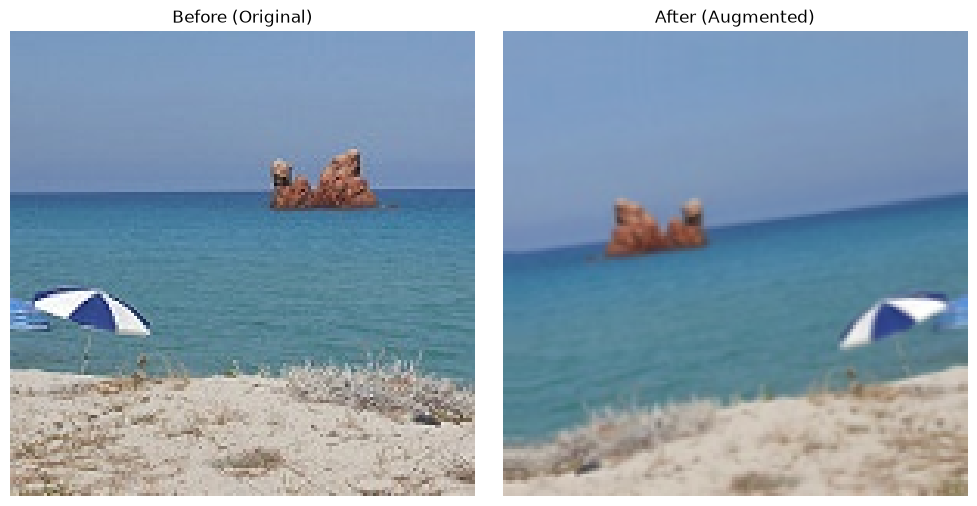

In [6]:
import matplotlib.pyplot as plt

for images , label in train_ds.take(1):

    original_img = images[0]

    augmented_img = data_augmentation(images[0:1])


    plt.figure(figsize=(10, 5))
  
    plt.subplot(1, 2, 1)
    plt.imshow(original_img.numpy().astype("uint8"))
    plt.title("Before (Original)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(augmented_img[0].numpy().astype("uint8"))
    plt.title("After (Augmented)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    break

**Prevents overfitting**: Stops the model from memorizing exact pixel coordinates.

**Improves generalization**: Exposes the CNN to realistic variations (tilted angles, zoomed views, flipped perspectives) so it recognizes objects in unseen, real-world photos.

## build CNN

In [7]:
model = keras.Sequential([
        layers.Rescaling(1./255, input_shape=(150, 150, 3)),
        layers.Conv2D(32, (3,3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3,3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(6, activation='softmax')
])

model.summary()

/home/emad/Desktop/image detection/venv/lib/python3.14/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

# train the model

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,                 # Stop if val_loss doesn't improve for 3 consecutive epochs
    restore_best_weights=True   # Keep the weights from the best epoch
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,                 # Reduce learning rate to 20% if stuck
    patience=2,
    min_lr=1e-6
)


EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr]
)

**training history**

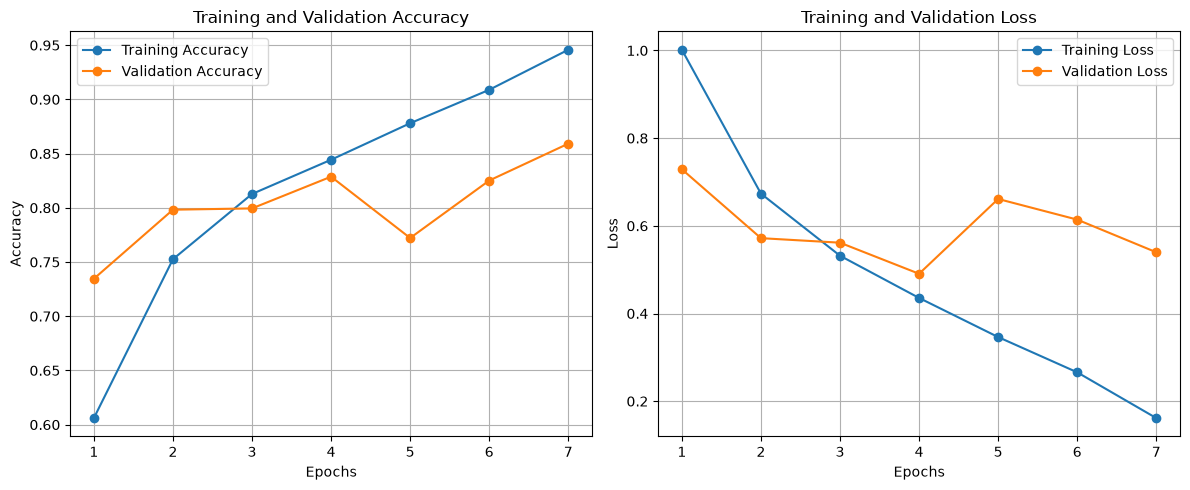

In [10]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Plot 1: Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Evaluation of the model

In [10]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Final Test Accuracy: {test_acc * 100:.2f}%")
print(f"Final Test Loss: {test_loss:.4f}")

81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.8307 - loss: 0.5139
Final Test Accuracy: 83.07%
Final Test Loss: 0.5139


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
for images, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
y_true = np.array(y_true)

y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

class_names = dataset.class_names


print(classification_report(y_true, y_pred, target_names=class_names))

81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step
              precision    recall  f1-score   support

   buildings       0.16      0.15      0.15       389
      forest       0.17      0.18      0.18       409
     glacier       0.17      0.18      0.17       448
    mountain       0.18      0.19      0.18       479
         sea       0.18      0.16      0.17       438
      street       0.16      0.16      0.16       407

    accuracy                           0.17      2570
   macro avg       0.17      0.17      0.17      2570
weighted avg       0.17      0.17      0.17      2570



## amelioration (configuration 2)

In [9]:
model_v2 = keras.Sequential([
    layers.Rescaling(1./255, input_shape=(150, 150, 3)),
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    
    layers.GlobalAveragePooling2D(),
    
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(6, activation='softmax')
])

model_v2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

# compile and train

In [10]:
model_v2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 120s 319ms/step - accuracy: 0.4491 - loss: 1.2647 - val_accuracy: 0.6017 - val_loss: 1.0170 - learning_rate: 0.0010
Epoch 2/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 119s 318ms/step - accuracy: 0.6028 - loss: 0.9714 - val_accuracy: 0.6562 - val_loss: 0.8598 - learning_rate: 0.0010
Epoch 3/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 118s 317ms/step - accuracy: 0.6487 - loss: 0.8802 - val_accuracy: 0.7037 - val_loss: 0.8054 - learning_rate: 0.0010
Epoch 4/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 111s 297ms/step - accuracy: 0.6860 - loss: 0.7993 - val_accuracy: 0.7085 - val_loss: 0.7802 - learning_rate: 0.0010
Epoch 5/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 118s 315ms/step - accuracy: 0.7012 - loss: 0.7695 - val_accuracy: 0.6911 - val_loss: 0.7697 - learning_rate: 0.0010
Epoch 6/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 117s 314ms/step - accuracy: 0.7286 - loss: 0.7071 - val_accuracy: 0.7413 - val_loss: 0.6773 - learning_rate: 0.0010
Epoch 7/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 116s 311ms/step - accura

**evaluate model 2 on test**

In [11]:
test_loss_v2, test_acc_v2 = model_v2.evaluate(test_ds)
print(test_acc_v2)
print(test_loss_v2)

81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - accuracy: 0.8183 - loss: 0.5019
0.8182879090309143
0.5019258856773376


**save model**

In [12]:
model_v2.save('../models/intel_classifier.keras')

**prediction function**

In [18]:
import numpy as np

def predict_image(image_path, model):
    class_names = dataset.class_names
    img = keras.utils.load_img(image_path, target_size=(150, 150))
    img_array = keras.utils.img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)
    predictions = model.predict(img_batch)
    predicted_index = np.argmax(predictions[0])
    predicted_class = class_names[predicted_index]
    probability = np.max(predictions[0]) * 100
    plt.imshow(img)
    plt.title(f"{predicted_class} ({probability:.2f}%)")
    plt.axis("off")
    plt.show()
    return predicted_class, probability

**predict an image**

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


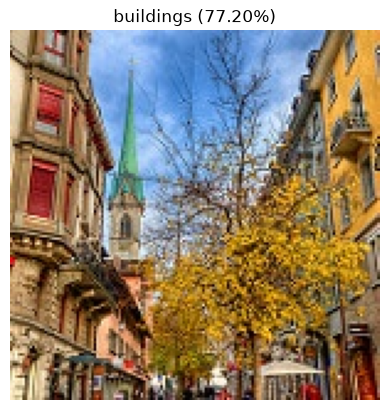

('buildings', np.float32(77.202515))

In [19]:
predict_image('../data/seg_pred/seg_pred/10004.jpg', model_v2)